In [3]:
%pylab inline
import smatch
from astropy.table import Table, vstack
import pltutil
import astropy.io.ascii as ascii

Populating the interactive namespace from numpy and matplotlib


In [4]:
cd wrkDir/

/work/xiangchong.li/work/galSim-HSC


In [3]:
# Initialization
cmpDir  =   'database/compare/'
catname8=   os.path.join(cmpDir,'scat-%s.fits' %'s18') # this is small catalog with S16A FDFC cut
catname9=   os.path.join(cmpDir,'scat-%s.fits' %'s19')
matname =   os.path.join(cmpDir,'match-s18-s19.fits')
pltDir  =   os.path.join(cmpDir,'plot','s18vs19')

In [ ]:
# Matching
data18  =   Table.read(catname8)
data19  =   Table.read(catname9)
match   =   smatch.match(data18['ra'],data18['dec'],0.4/3600.,\
    data19['ra'],data19['dec'],maxmatch=1)      # For a galaxy in S19A,
                                                # Find the closest galaxy in S18A
index   =   np.unique(match['i1'],return_index=True)[1]  # Make sure one to one match
match   =   match[index]
data18  =   data18[match['i1']]
data19  =   data19[match['i2']]
# Record the s18 measuremnt to s19 catalog
data19['object_id18']=   data18['object_id']
data19['snr18']   =   data18['snr']
data19['res18']   =   data18['res']
data19['mag18']   =   data18['mag']
data19['absE18']  =   data18['absE']
data19['traceR18']=   data18['traceR']
data19['TPid18']  =   data18['TPid']
data19['scat_id18']=  match['i1']
data19['scat_id'] =   match['i2']
data19['dmag1819']=data19['mag18']-data19['mag']
data19.write(matname)

In [4]:
try:
    data19 is None
except:
    data19=Table.read(matname)
# Plot dmag vs mag
if 'dmag1819' in data19.colnames:
    data19['dmag1819'].name='dmag'
pergroup=1
colns1=['dmag']
colns2=['mag']
fig     =   plt.figure(figsize=(5*pergroup, 5))
axes    =   []
for j in range(pergroup):
    axes.append(fig.add_subplot(1,pergroup,j+1))
pltUtil.cols2DPlot(data19,colns1,colns2,axes,pltDir=pltDir,color='Greys',ngridH=128)

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/matplotlib/pyplot.py:514: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  max_open_warning, RuntimeWarning)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in less
  result = getattr(super(), op)(other)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in greater
  result = getattr(super(), op)(other)


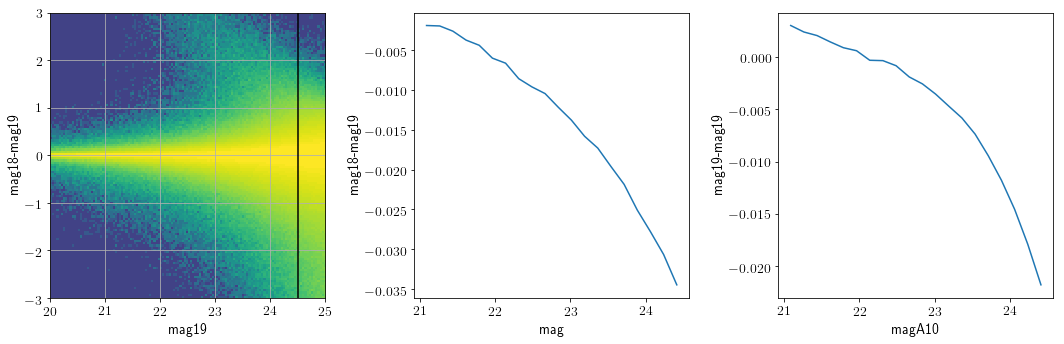

In [42]:
def makeMagdMagPlot(data,ax,title,xmin,xmax,ymin,ymax):
    dextent =   [xmin,xmax,ymin,ymax]
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    bdry    =   np.percentile(data,np.arange(1,99,1))
    norm2   =   matplotlib.colors.BoundaryNorm(bdry,ncolors=256)
    im      =   ax.imshow(data,extent=dextent,norm=norm2,origin='lower',aspect='auto')
    if title is not None:
        ax.set_title(title)
    plt.grid()
    return

fig     =   plt.figure(figsize=(5*3, 5))
pltDat  =   pyfits.getdata('database/compare/plot/s18vs19/hist2d-dmag-mag_data.fits')

ax      =   fig.add_subplot(1,3,1)
makeMagdMagPlot(pltDat,ax,None,xmin=20,xmax=25,ymin=-3,ymax=3)
ax.set_xlabel('mag19')
ax.set_ylabel('mag18-mag19')
axvline(24.5,c='black')
mask1=  (data19['mag']<24.5) \
        &(data19['res']>0.3) \
        &(data19['absE']<2.) \
        &(data19['logb']<-0.38) \
        &(data19['snr']>10.) \
        &(data19['dmag']>-10.)\
        &(data19['dmag']<10.)
mask2=mask1&(data19['magA10']<25.5)
dmag=data19['dmag']

ax      =   fig.add_subplot(1,3,2)
dmagHist=np.histogram(data19['mag'][mask2],bins=20,weights=dmag[mask2],range=(21,24.5))[0]
numHist,binHist=np.histogram(data19['mag'][mask2],bins=20,range=(21,24.5))
dmagAve=dmagHist/numHist
ax.plot((binHist[:-1]+binHist[1:])/2.,dmagAve)
ax.set_xlabel('mag')
ax.set_ylabel('mag18-mag19')

ax      =   fig.add_subplot(1,3,3)
dmagHist=np.histogram(data19['magA10'][mask2],bins=20,weights=dmag[mask2],range=(21,24.5))[0]
numHist,binHist=np.histogram(data19['magA10'][mask2],bins=20,range=(21,24.5))
dmagAve=dmagHist/numHist
ax.plot((binHist[:-1]+binHist[1:])/2.,dmagAve)
ax.set_xlabel('magA10')
ax.set_ylabel('mag19-mag19')
plt.tight_layout()
fig

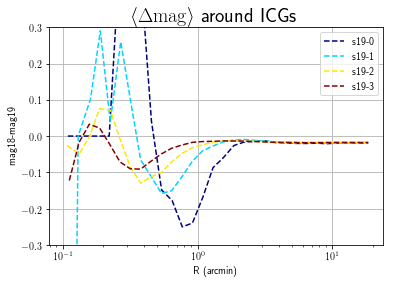

In [64]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d19=ascii.read('database/compare/plot/s18vs19/cor2PNK-wl2-Wang-mag-mag-g%d-s18-s19.csv' %ig)
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel('mag18-mag19')
plt.xscale('log')
plt.ylim(-0.3,0.3)
#plt.yscale('log')
plt.title(r'$\langle\Delta \rm{mag}\rangle$ around ICGs',fontsize=20)


plt.grid()
plt.legend(loc='upper right')